# Length cutoff analysis

Reads a recorded `python -m length_analysis --mode deletion` run over the 1,074-candidate short
list and plots the Figure 4 length-variation panels.

`k = round(p * L)` residues are removed from one terminus, **half-up**, for p = 0.05, 0.1, 0.2.
Each (parent, terminus, p) cell is a single deterministic truncation, folded on its own — there
is no replicate axis and no `sd_` column, unlike the mutation sweep. Cells with `k == 0` are
skipped by the runner, so the shortest peptides have no p = 0.05 row.

Inputs (CSV file contracts, no module imports):

- `length_deletion_curves.csv` — one row per (parent, terminus, p): the truncated variant's score
- `length_deletion_robustness.csv` — one row per (parent, terminus): parent baseline and collapse

The run is **pinned by `RUN_ID`** rather than taken as the newest on disk, so the panels below
always describe one recorded prediction run. `RUN_ID = None` falls back to the newest.

Two model outputs are used throughout, named as in `mutation_analysis.ipynb`:

- **σ (sigma score)** — the **raw logit difference**, `logit_AMP − logit_nonAMP`, straight from the
  GNN head. Unbounded, signed.
- **P(AMP)** — the calibrated probability. Under temperature scaling that is `sigmoid(σ / T)`, so
  P ≥ 0.5 and σ > 0 select exactly the same peptides. Only Platt scaling carries an intercept and
  so moves the 0.5 crossing off σ = 0; `SIGMA_THRESHOLD` is read from the run's own checkpoint
  rather than assumed, and the AMP population is taken from the `pred` / `parent_pred` columns the
  runner wrote.

**Panels plot absolute σ and P(AMP), not Δ.** A Δ curve shows how far a peptide fell but not
where it started, which is the quantity that decides whether a truncated variant is still an AMP.
Every curve therefore carries its untruncated parent score as its own **p = 0** point, and the
AMP threshold is drawn on the same axis. The `delta_*` columns are still in the source CSVs
(variant − original) and are reported in the summary table beside the absolute means.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Recorded run over the 1,074-candidate short list, on checkpoints/gnn/gnn_vae_qsar.
# The loader prints the checkpoint and calibration it actually used.
# None takes the newest run on disk instead.
RUN_ID = "length-deletion-2026-11-06_01-46"


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "length_analysis").is_dir():
            return path
    raise FileNotFoundError("Could not locate the repository root.")


def resolve_run_dir(data_root: Path, run_id: str | None, filename: str) -> Path:
    results_root = data_root / "results"
    if run_id is not None:
        return results_root / "runs" / run_id
    candidates = list((results_root / "runs").glob(f"*/{filename}"))
    if not candidates:
        return results_root
    return max(candidates, key=lambda path: path.stat().st_mtime_ns).parent


def calibration_of(run_directory: Path) -> tuple[str, float, str]:
    """``(method, sigma at P(AMP) = 0.5, description)`` for the run's checkpoint.

    Only Platt carries an intercept, so it is the only method whose 0.5 crossing
    moves off sigma = 0 — switching methods changes the hard AMP call and not just
    the probability. The resolution order mirrors `gnn_minimal/core/calibration.py`:
    an explicit `fitting`, else temperature, else Platt, else uncalibrated softmax.
    """
    config = json.loads((run_directory / "run_manifest.json").read_text())["config"]
    model_dir = Path(config["arguments"]["checkpoint_dir"])
    if not model_dir.is_dir():
        model_dir = ROOT / "checkpoints" / "gnn" / model_dir.name
    method = config["effective"].get("fitting") or next(
        (name for name in ("temperature", "platt")
         if (model_dir / f"gnn_{name}_scaling").is_file()),
        "softmax",
    )
    if method == "temperature":
        payload = json.loads((model_dir / "gnn_temperature_scaling").read_text())
        return method, 0.0, f"{model_dir.name}, temperature-scaled (T = {payload['temperature']:.5f})"
    if method == "platt":
        payload = json.loads((model_dir / "gnn_platt_scaling").read_text())
        threshold = -float(payload["intercept"]) / float(payload["coef"])
        return method, threshold, (
            f"{model_dir.name}, Platt-scaled "
            f"(coef = {payload['coef']:.3f}, intercept = {payload['intercept']:.3f})"
        )
    return method, 0.0, f"{model_dir.name}, uncalibrated softmax"


ROOT = find_repo_root()
DATA_ROOT = ROOT / "data" / "proteomes" / "1k_confirmed_candidates"
RUN_DIR = resolve_run_dir(DATA_ROOT, RUN_ID, "length_deletion_curves.csv")
CURVES_CSV = RUN_DIR / "length_deletion_curves.csv"
ROBUSTNESS_CSV = RUN_DIR / "length_deletion_robustness.csv"
FITTING, SIGMA_THRESHOLD, CALIBRATION = calibration_of(RUN_DIR)

TERMINUS_ORDER = ["N", "C"]
TERMINUS_LABEL = {"N": "N-terminal deletion", "C": "C-terminal deletion"}
TERMINUS_COLOR = {"N": "#2a78d6", "C": "#eb6834"}
TERMINUS_MARKER = {"N": "o", "C": "s"}
TERMINUS_CMAP = {"N": "Blues", "C": "Oranges"}

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "monospace"
# TrueType (Type 42) so PDF text stays editable vectors instead of raster outlines.
plt.rcParams["pdf.fonttype"] = 42

SPINE_COLOR = "#2b2b2b"
LABEL_SIZE = 10.5
TITLE_SIZE = 12


def style_axes(ax, grid_axis: str = "y") -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(SPINE_COLOR)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.grid(axis=grid_axis, linestyle="--", linewidth=0.6, alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)


print("Run:        ", RUN_DIR.name, "(pinned)" if RUN_ID else "(newest)")
print("Curves:     ", CURVES_CSV)
print("Robustness: ", ROBUSTNESS_CSV)
print("Calibration:", CALIBRATION)
print(f"AMP call at  sigma > {SIGMA_THRESHOLD:.3f}  /  P(AMP) >= 0.5")

Run:         length-deletion-2026-11-06_01-46 (pinned)
Curves:      /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/1k_confirmed_candidates/results/runs/length-deletion-2026-11-06_01-46/length_deletion_curves.csv
Robustness:  /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/1k_confirmed_candidates/results/runs/length-deletion-2026-11-06_01-46/length_deletion_robustness.csv
Calibration: gnn_vae_qsar, temperature-scaled (T = 0.76577)
AMP call at  sigma > 0.000  /  P(AMP) >= 0.5


In [2]:
curves = pd.read_csv(CURVES_CSV)
robustness = pd.read_csv(ROBUSTNESS_CSV)

# Project vocabulary is sigma, not margin. The source CSVs still carry the
# margin_* / logit_margin names written by length_analysis.
SIGMA_RENAMES = {
    "parent_logit_margin": "parent_sigma",
    "margin_auc": "deletion_sigma_auc",
    "margin_slope": "sigma_slope",
    "logit_margin": "sigma",
    "delta_logit_margin": "delta_sigma",
}
curves = curves.rename(columns=SIGMA_RENAMES)
robustness = robustness.rename(columns=SIGMA_RENAMES)

PARENT_COLUMNS = ["parent_id", "length", "parent_pred", "parent_prob_AMP", "parent_sigma"]
parents = robustness[PARENT_COLUMNS].drop_duplicates("parent_id")

curves = curves.merge(parents, on="parent_id", how="left")
# `pred` is the call the runner made under this run's own calibration, so it stays
# correct even when the 0.5 crossing sits off sigma = 0.
curves["called_AMP"] = curves["pred"].astype(float)

# Figures restrict to candidates the model already calls AMP.
amp_parents = parents[parents["parent_pred"] == 1]
amp_curves = curves[curves["parent_id"].isin(amp_parents["parent_id"])]

P_LEVELS = sorted(curves["p"].unique())

# Each absolute curve starts at its own untruncated parent score, so p = 0 is the
# original prediction rather than an extra variant.
ORIGINAL_OF = {
    "sigma": "parent_sigma",
    "prob_AMP": "parent_prob_AMP",
    "called_AMP": "parent_pred",
    "delta_sigma": 0.0,
    "delta_prob_AMP": 0.0,
    "k": 0,
}


def with_original(frame: pd.DataFrame, columns: dict[str, object] = ORIGINAL_OF) -> pd.DataFrame:
    """Prepend a p = 0 row per (parent, terminus) holding the untruncated scores.

    ``columns`` maps each variant column to the parent column it starts from, or to
    a constant where no parent column exists.
    """
    keep = ["parent_id", "terminus", "p", *columns]
    start = frame.drop_duplicates(["parent_id", "terminus"]).copy()
    start["p"] = 0.0
    for value, origin in columns.items():
        start[value] = start[origin] if isinstance(origin, str) else origin
    return pd.concat([start[keep], frame[keep]], ignore_index=True)


anchored = with_original(amp_curves)
P_LEVELS_FROM_ORIGINAL = [0.0, *P_LEVELS]

print(f"parents:    {len(parents):,}   called AMP: {len(amp_parents):,}")
print(f"curve rows: {len(curves):,}   AMP-only: {len(amp_curves):,}"
      f"   with p = 0 anchor: {len(anchored):,}")
print(f"p levels:   {P_LEVELS}")
print(f"termini:    {sorted(curves['terminus'].unique())}")
# k == 0 cells are dropped by the runner, so cell counts fall at the smallest p.
print(curves.groupby(["terminus", "p"]).size().rename("cells"))
robustness.head()

parents:    1,074   called AMP: 578
curve rows: 6,426   AMP-only: 3,458   with p = 0 anchor: 4,614
p levels:   [np.float64(0.05), np.float64(0.1), np.float64(0.2)]
termini:    ['C', 'N']
terminus  p   
C         0.05    1065
          0.10    1074
          0.20    1074
N         0.05    1065
          0.10    1074
          0.20    1074
Name: cells, dtype: int64


,run_id,parent_id,terminus,sequence,length,parent_pred,parent_prob_AMP,parent_sigma,n_variants,n_p_levels,mean_k,retention,retention_first_p,retention_last_p,mean_prob_AMP,mean_delta_prob_AMP,deletion_sigma_auc,sigma_slope,gene_names,leading_razor_protein
0,2026-11-06_01-46,SEQ_1,C,LSLVTKKKRFWCWQRPKYQFL,21,0,0.344183,-0.493699,3,3,2.333333,0.333333,0,1,0.442527,0.098344,-0.158804,2.987828,DFNA5,O60443
1,2026-11-06_01-46,SEQ_1,N,LSLVTKKKRFWCWQRPKYQFL,21,0,0.344183,-0.493699,3,3,2.333333,0.666667,1,1,0.608378,0.264195,0.306450,4.092269,DFNA5,O60443
2,2026-11-06_01-46,SEQ_2,C,RMFRGSLYKRYPSLWRRL,18,1,0.978130,2.910319,3,3,2.333333,1.000000,1,1,0.902608,-0.075521,1.657967,-6.759468,SMARCB1,Q12824
3,2026-11-06_01-46,SEQ_2,N,RMFRGSLYKRYPSLWRRL,18,1,0.978130,2.910319,3,3,2.333333,1.000000,1,1,0.963352,-0.014778,3.115719,0.628619,SMARCB1,Q12824
4,2026-11-06_01-46,SEQ_3,C,SLVTKKKRFWCWQRPKYQFL,20,1,0.589915,0.278444,3,3,2.333333,0.666667,0,1,0.504169,-0.085745,0.062371,1.823624,DFNA5,O60443


## Figure 4 — number of AMP candidates as a function of score and p

One panel per terminus. The x-axis is the **absolute** score of the variant, the y-axis is the
deletion level p, and the colour is the number of AMP candidates falling in that cell. Rows are
drawn at equal height, so the levels read as categories rather than as a 0–0.2 axis.

The bottom row, `0 (original)`, is the untruncated population, so each panel reads as the whole
score distribution sliding toward the AMP threshold rather than as a cloud of Δ values with no
origin. The threshold line is where the run's own calibration puts P(AMP) = 0.5.

Only the AMP-called parents are counted, the same population as the curves below. σ bin edges are
symmetric about the threshold at the 99th percentile of |σ − threshold|; P(AMP) is binned over
its full 0–1 range. Tails are clipped into the end bins so no peptide is dropped from the counts.

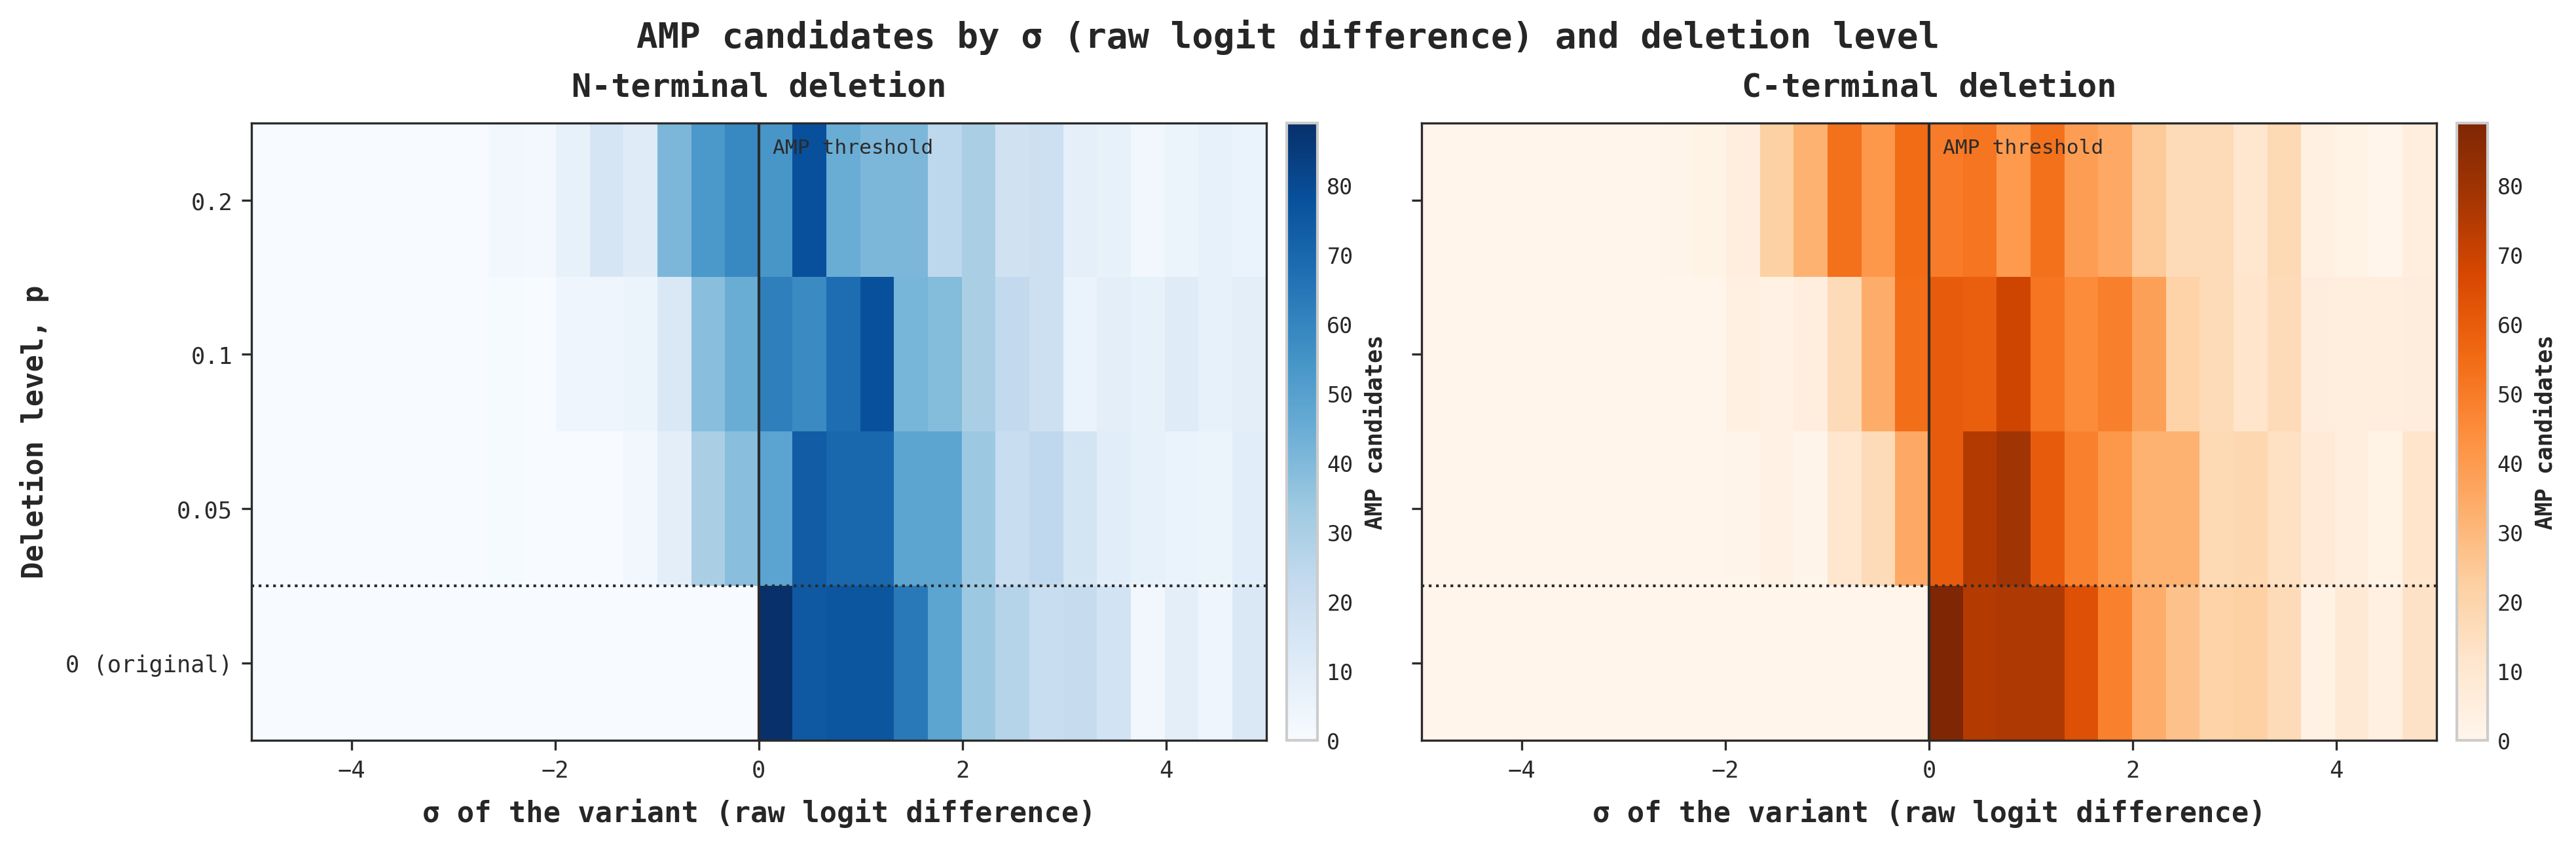

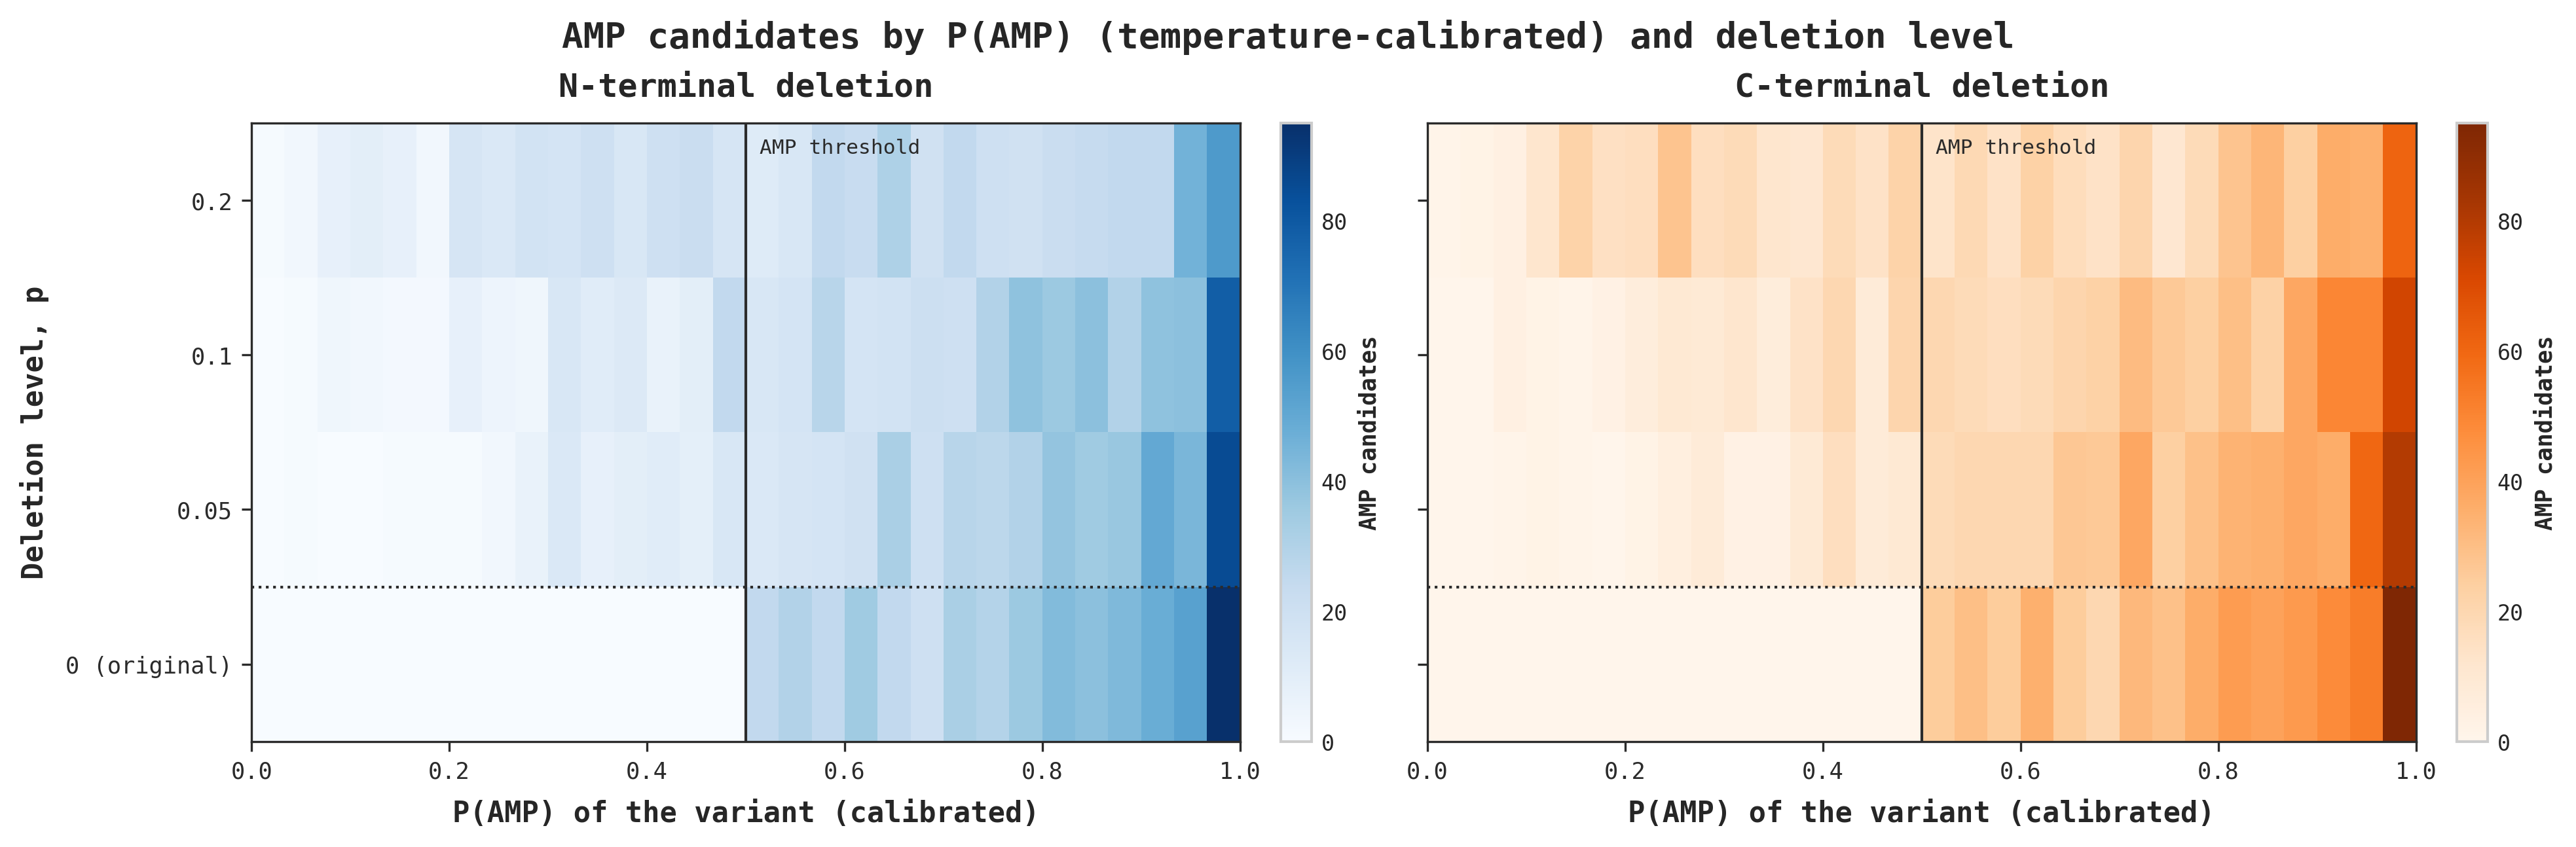

In [3]:
def threshold_edges(values: pd.Series, bins: int = 30, percentile: float = 99.0) -> np.ndarray:
    """Bin edges symmetric about the AMP threshold, out to a percentile of the spread."""
    span = float(np.nanpercentile(np.abs(values - SIGMA_THRESHOLD), percentile))
    return np.linspace(SIGMA_THRESHOLD - span, SIGMA_THRESHOLD + span, bins + 1)


def deletion_heatmap(frame: pd.DataFrame, value: str, edges: np.ndarray, threshold: float,
                     value_label: str, title: str) -> None:
    """Counts of AMP candidates per (score bin, p) cell, one panel per terminus."""
    levels = P_LEVELS_FROM_ORIGINAL
    grids = {
        terminus: np.vstack([
            np.histogram(
                frame.loc[(frame["terminus"] == terminus) & (frame["p"] == level), value]
                .clip(edges[0], edges[-1]),
                bins=edges,
            )[0]
            for level in levels
        ])
        for terminus in TERMINUS_ORDER
    }
    peak = max(int(grid.max()) for grid in grids.values())

    figure, axes = plt.subplots(1, len(TERMINUS_ORDER), figsize=(13.0, 4.2), dpi=300,
                               sharey=True, layout="constrained")
    for axis, terminus in zip(axes, TERMINUS_ORDER):
        mesh = axis.pcolormesh(edges, np.arange(len(levels) + 1), grids[terminus],
                               cmap=TERMINUS_CMAP[terminus], vmin=0, vmax=peak)
        axis.axvline(threshold, color=SPINE_COLOR, linewidth=1.0)
        axis.annotate("AMP threshold", xy=(threshold, len(levels)),
                      textcoords="offset points", xytext=(5, -11),
                      fontsize=7.5, color=SPINE_COLOR)
        # The p = 0 row is the untruncated population, separated from the swept levels.
        axis.axhline(1.0, color=SPINE_COLOR, linewidth=1.0, linestyle=":")
        axis.set_yticks(np.arange(len(levels)) + 0.5)
        axis.set_yticklabels(["0 (original)", *(f"{level:g}" for level in P_LEVELS)])
        axis.set_title(TERMINUS_LABEL[terminus], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
        axis.set_xlabel(value_label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
        axis.grid(False)
        axis.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)
        for side in ("top", "right", "left", "bottom"):
            axis.spines[side].set_visible(True)
            axis.spines[side].set_color(SPINE_COLOR)
            axis.spines[side].set_linewidth(0.8)
        bar = figure.colorbar(mesh, ax=axis, pad=0.02)
        bar.set_label("AMP candidates", fontsize=8.5, fontweight="bold")
        bar.ax.tick_params(labelsize=8)

    axes[0].set_ylabel("Deletion level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    figure.suptitle(title, fontsize=TITLE_SIZE + 1, fontweight="bold")
    plt.show()


deletion_heatmap(
    anchored,
    "sigma",
    threshold_edges(anchored["sigma"]),
    SIGMA_THRESHOLD,
    "σ of the variant (raw logit difference)",
    "AMP candidates by σ (raw logit difference) and deletion level",
)
deletion_heatmap(
    anchored,
    "prob_AMP",
    np.linspace(0.0, 1.0, 31),
    0.5,
    "P(AMP) of the variant (calibrated)",
    f"AMP candidates by P(AMP) ({FITTING}-calibrated) and deletion level",
)

## Absolute score versus p for AMP candidates

One panel per terminus. Faint lines are individual peptides; the bold line is the mean across them
with a 95% confidence interval. Both σ and P(AMP) are plotted on their own absolute scale, as in
`mutation_analysis.ipynb`.

Each peptide's curve starts at **p = 0**, its untruncated score, so the panel shows where the
population began and how close to the AMP threshold it ends up — not only how far it moved. The
mean is annotated at p = 0 and at the largest p, and the dashed line is the AMP threshold.

Peptides with no p = 0.05 variant (k would round to 0) leave a gap at that level rather than
being dropped from the panel.

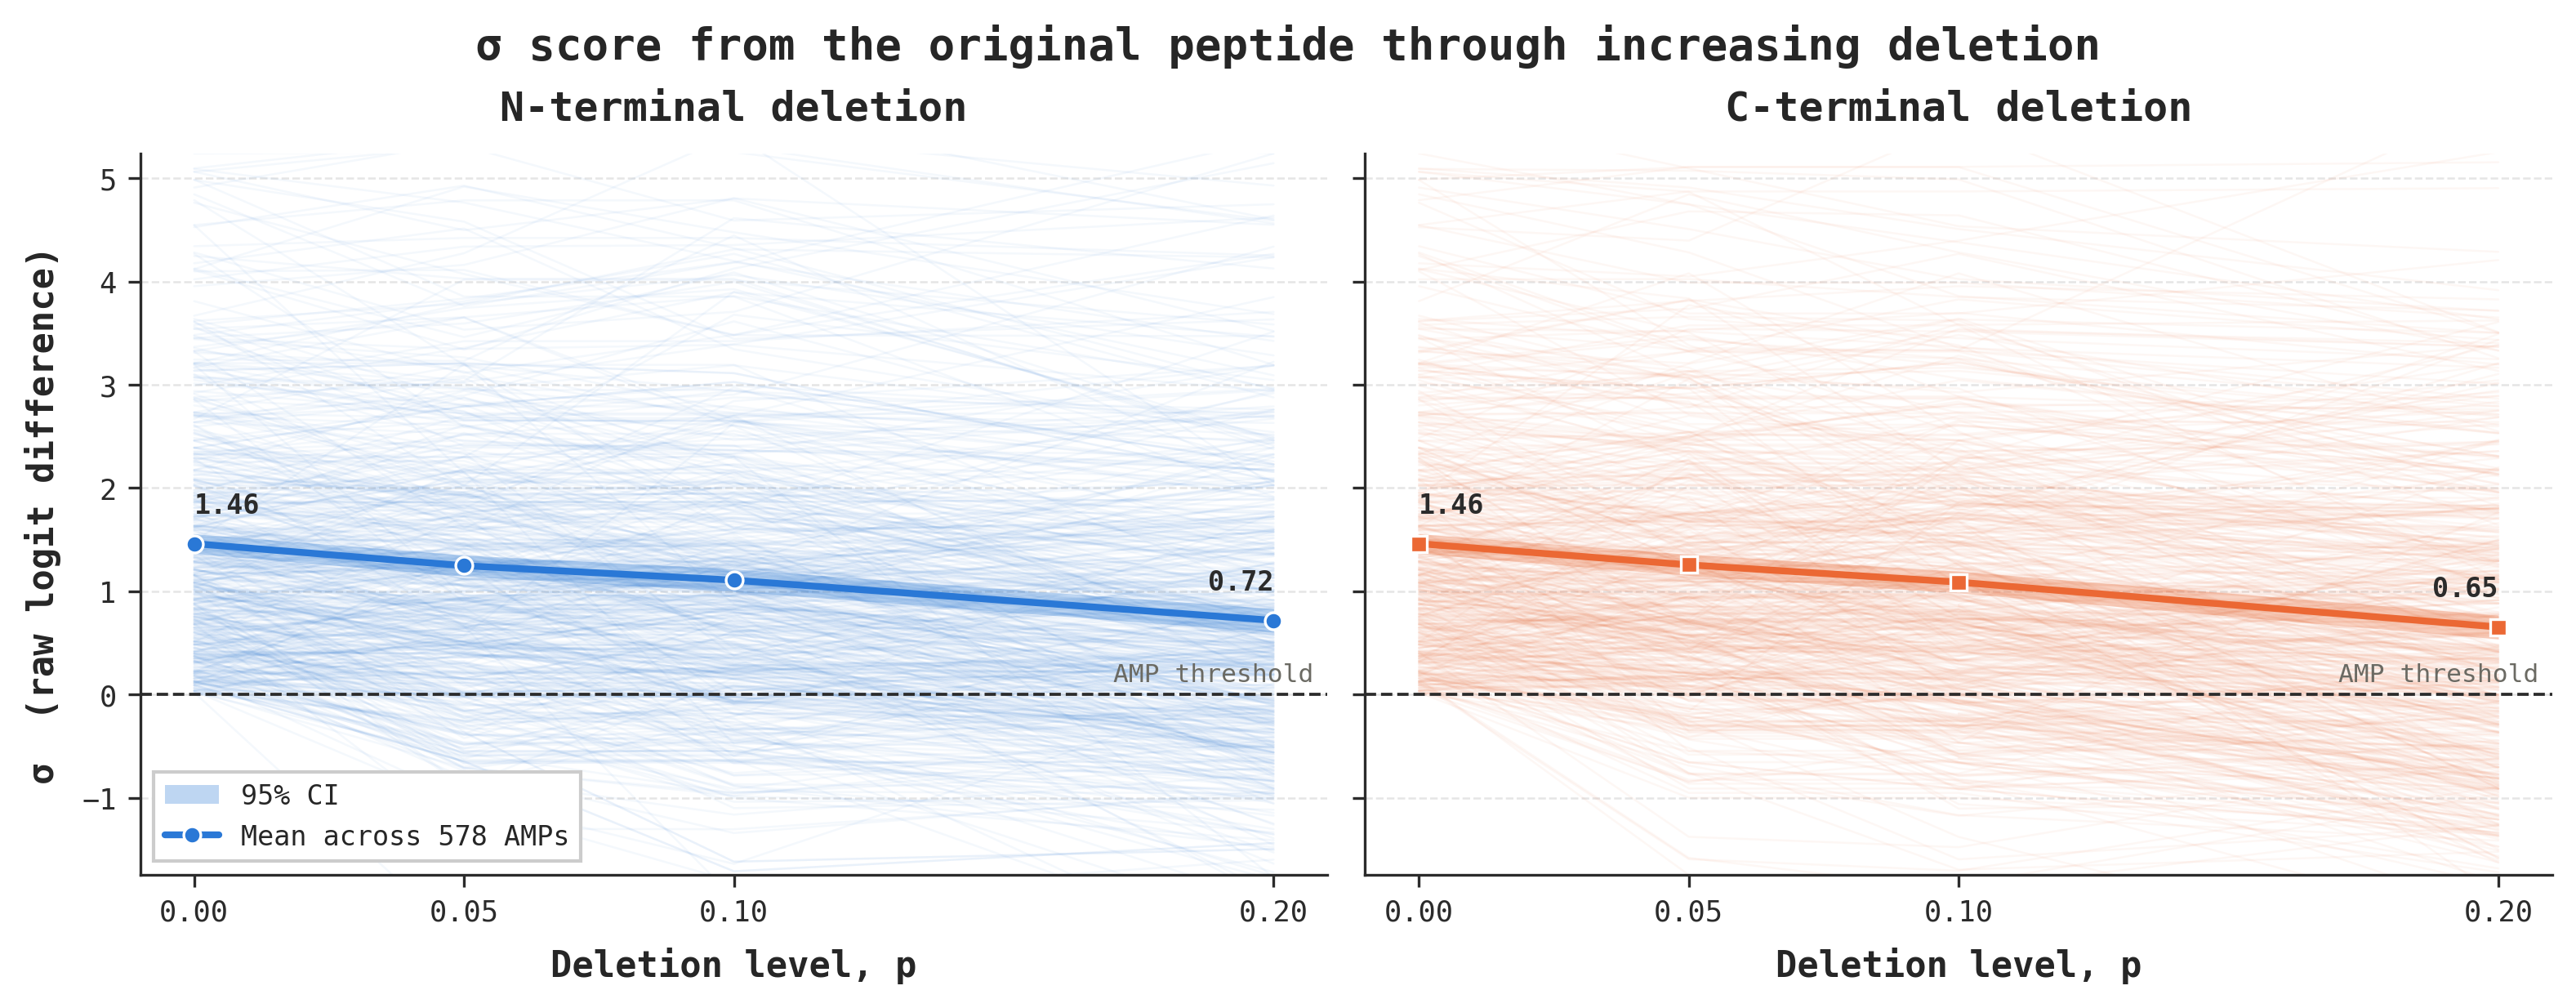

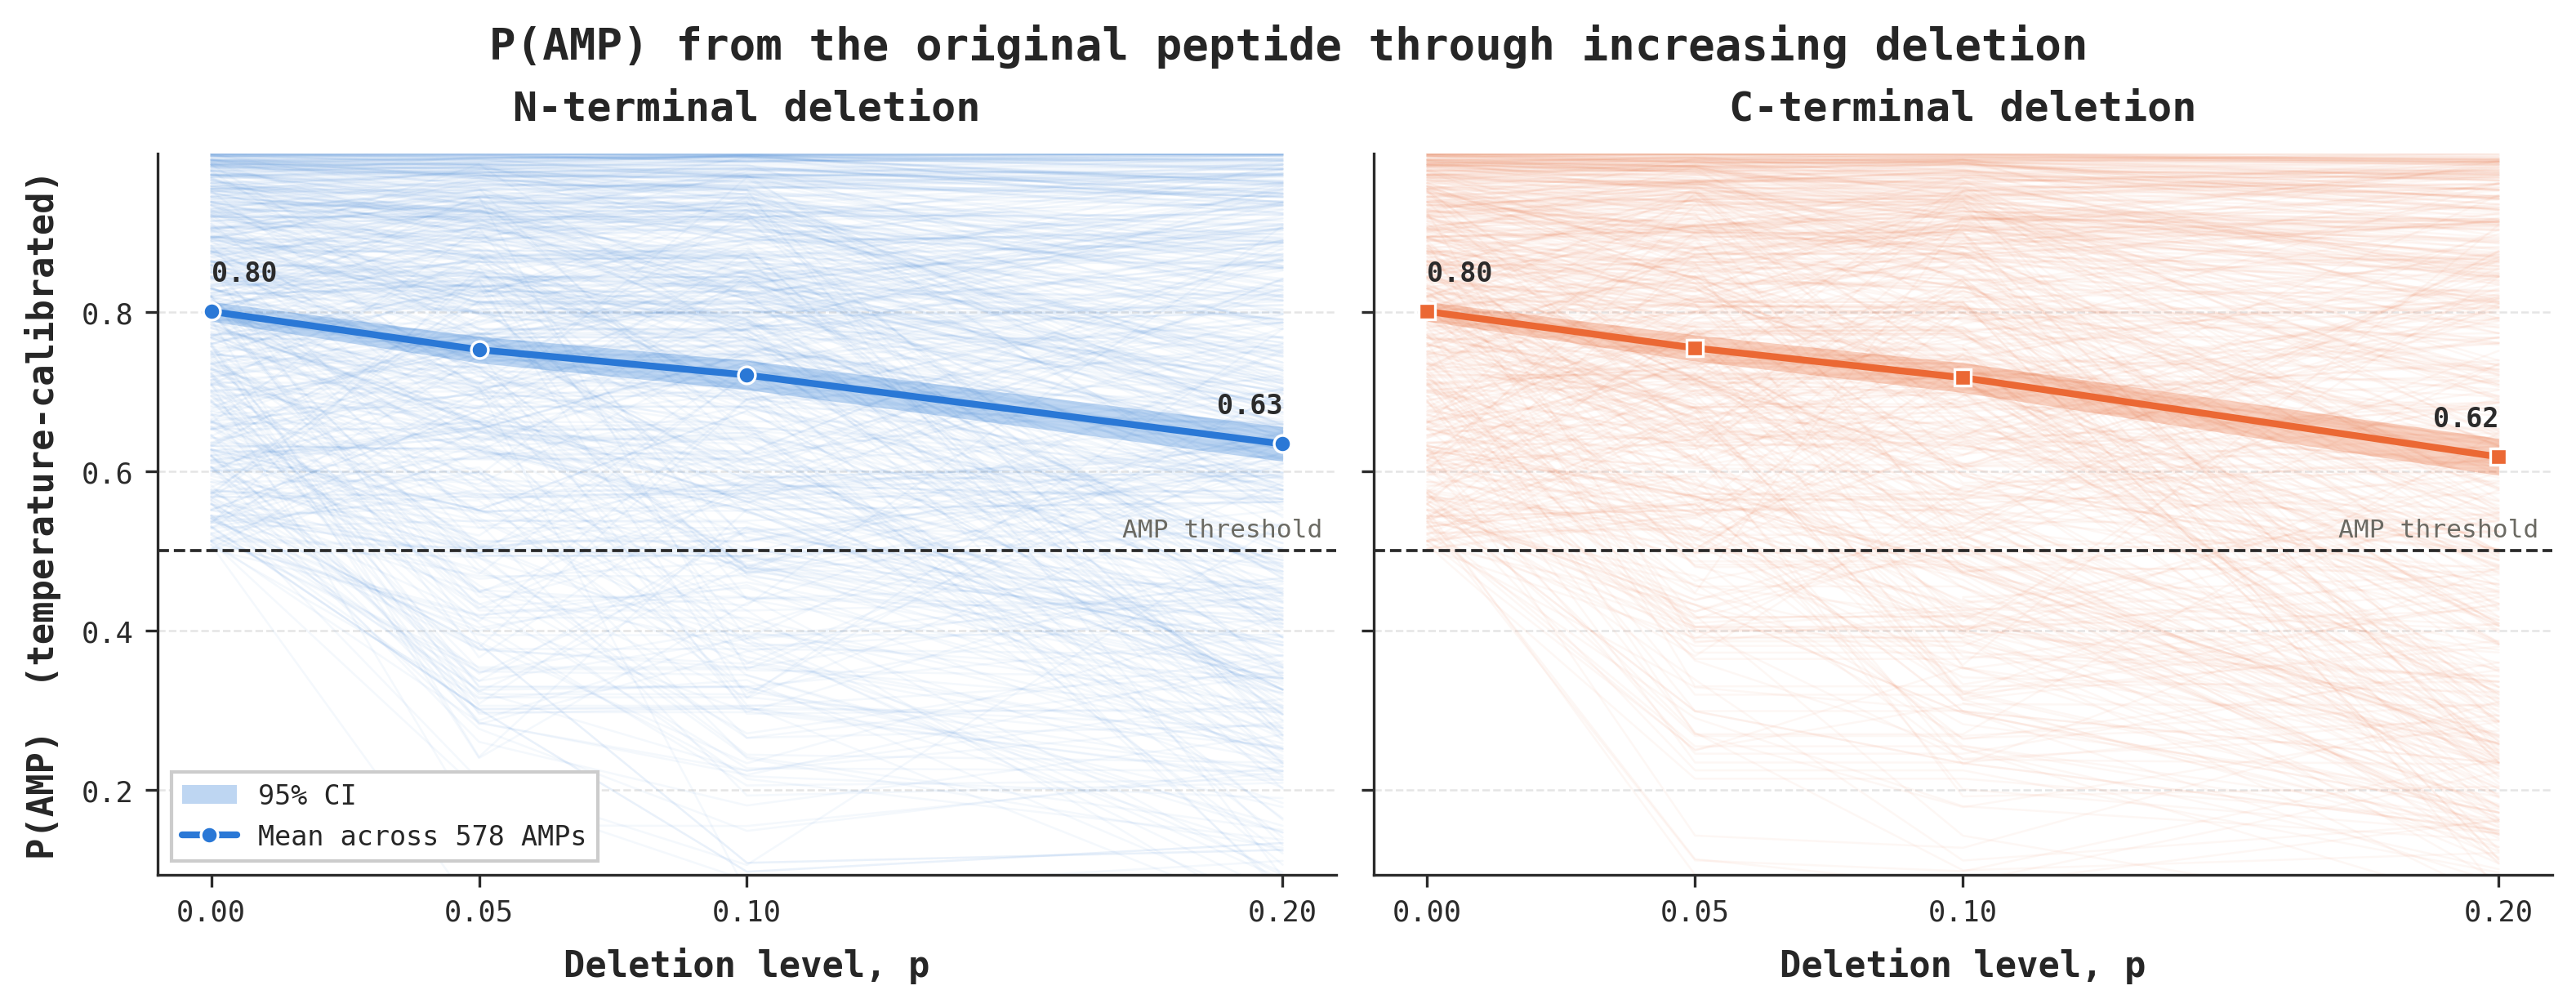

In [4]:
def mean_ci(frame: pd.DataFrame, value: str) -> pd.DataFrame:
    """Per-p mean across parents with a normal-approximation 95% CI."""
    stats = frame.groupby("p")[value].agg(["mean", "std", "count"])
    half_width = 1.96 * stats["std"] / np.sqrt(stats["count"])
    stats["low"] = stats["mean"] - half_width
    stats["high"] = stats["mean"] + half_width
    return stats.reset_index()


def plot_score_vs_p(frame: pd.DataFrame, value: str, threshold: float,
                    y_label: str, title: str) -> None:
    figure, axes = plt.subplots(1, len(TERMINUS_ORDER), figsize=(10.4, 4.0), dpi=300,
                               sharey=True, layout="constrained")
    for axis, terminus in zip(axes, TERMINUS_ORDER):
        subset = frame[frame["terminus"] == terminus]
        color = TERMINUS_COLOR[terminus]

        spaghetti = subset.pivot(index="p", columns="parent_id", values=value)
        axis.plot(spaghetti.index, spaghetti.to_numpy(), color=color, alpha=0.05, linewidth=0.6)

        stats = mean_ci(subset, value)
        axis.fill_between(stats["p"], stats["low"], stats["high"], color=color, alpha=0.3,
                          linewidth=0, label="95% CI")
        axis.plot(stats["p"], stats["mean"], color=color, linewidth=2.0,
                  marker=TERMINUS_MARKER[terminus], markersize=5, markeredgecolor="white",
                  markeredgewidth=0.8, label=f"Mean across {subset['parent_id'].nunique():,} AMPs")
        # The original and final means, so the absolute drop is readable off the panel.
        for index, align in ((0, "left"), (-1, "right")):
            axis.annotate(f"{stats['mean'].iloc[index]:.2f}",
                          (stats["p"].iloc[index], stats["mean"].iloc[index]),
                          textcoords="offset points", xytext=(0, 9), ha=align,
                          fontsize=8, fontweight="bold", color=SPINE_COLOR)

        axis.axhline(threshold, color=SPINE_COLOR, linewidth=0.9, linestyle="--")
        axis.annotate("AMP threshold", xy=(1.0, threshold), xycoords=("axes fraction", "data"),
                      textcoords="offset points", xytext=(-4, 4), ha="right",
                      fontsize=7.5, color="#6b6a63")
        axis.set_title(TERMINUS_LABEL[terminus], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
        axis.set_xlabel("Deletion level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
        axis.set_xticks(P_LEVELS_FROM_ORIGINAL)
        style_axes(axis)

    # Clip to the bulk so the means stay legible; a few peptides run far past this.
    low, high = np.nanpercentile(frame[value], [0.5, 99.5])
    axes[0].set_ylim(min(low, threshold - 0.05 * (high - low)),
                     max(high, threshold + 0.05 * (high - low)))
    axes[0].set_ylabel(y_label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    axes[0].legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
    figure.suptitle(title, fontsize=TITLE_SIZE + 1, fontweight="bold")
    plt.show()


plot_score_vs_p(
    anchored,
    "sigma",
    SIGMA_THRESHOLD,
    "σ  (raw logit difference)",
    "σ score from the original peptide through increasing deletion",
)
plot_score_vs_p(
    anchored,
    "prob_AMP",
    0.5,
    f"P(AMP)  ({FITTING}-calibrated)",
    "P(AMP) from the original peptide through increasing deletion",
)

## AMP call retention versus p

The fraction of the AMP-called candidates still called AMP after truncation. Deletion is
deterministic, so retention here is a fraction *across peptides* at each (terminus, p) — not
across replicates of one peptide, as it is in the mutation sweep.

The curve starts at p = 0, where retention is 1 by construction: that is the population the
figure conditions on.

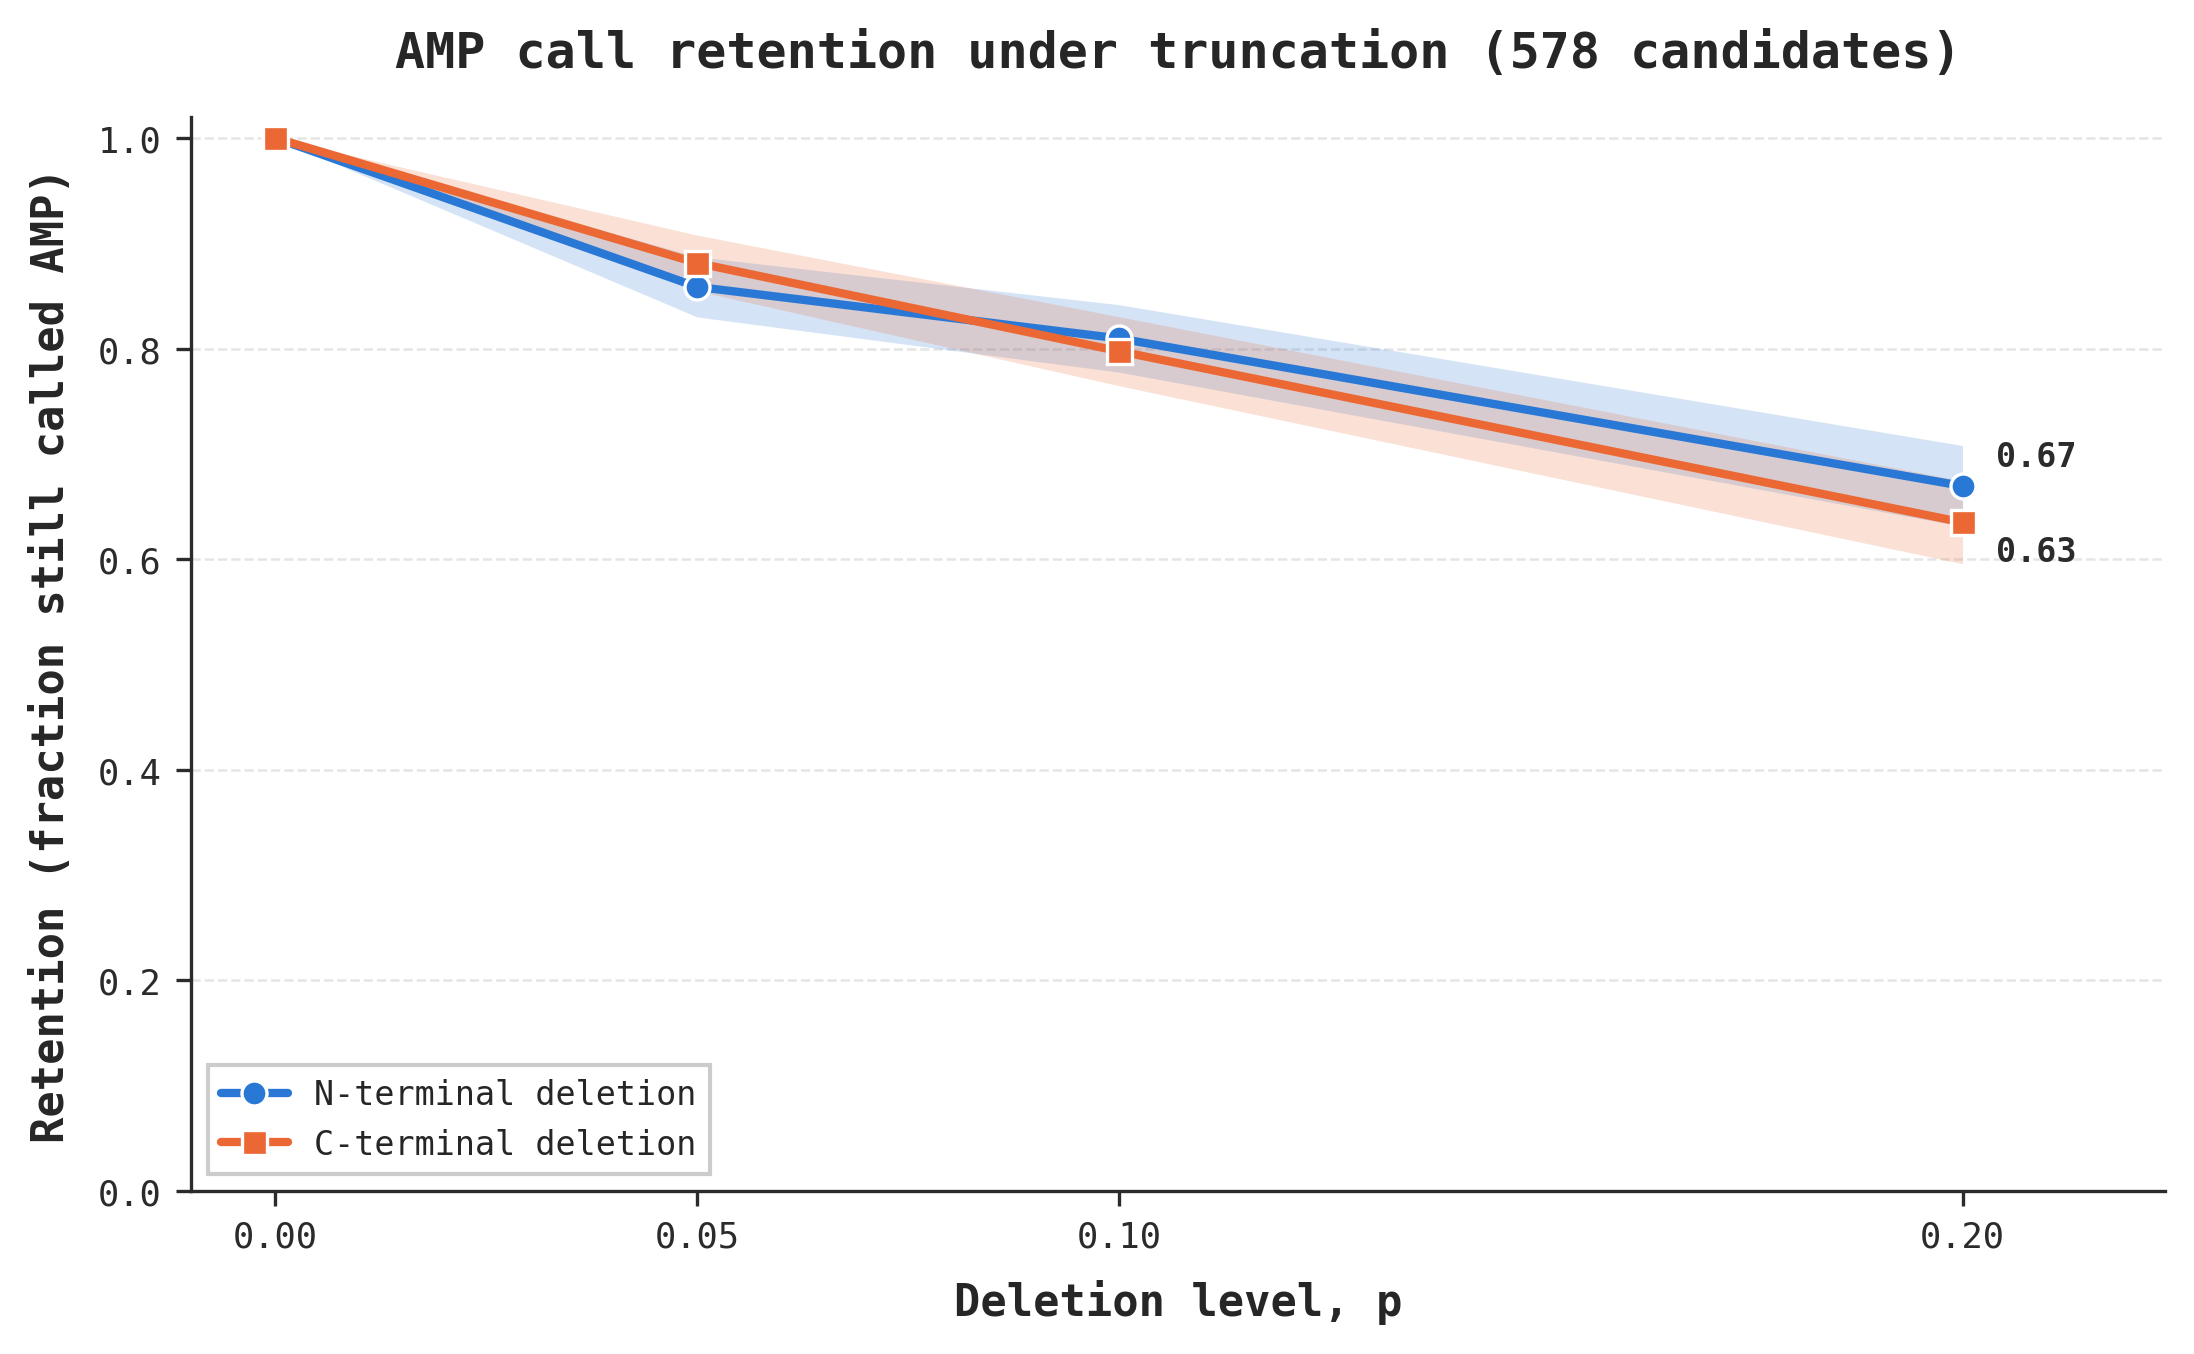

In [5]:
LABEL_OFFSET = {"N": 7.0, "C": -7.0}

figure, axis = plt.subplots(figsize=(7.2, 4.4), dpi=300, layout="constrained")
for terminus in TERMINUS_ORDER:
    stats = mean_ci(anchored[anchored["terminus"] == terminus], "called_AMP")
    color = TERMINUS_COLOR[terminus]
    axis.fill_between(stats["p"], stats["low"], stats["high"], color=color, alpha=0.2, linewidth=0)
    axis.plot(stats["p"], stats["mean"], color=color, linewidth=2.0,
              marker=TERMINUS_MARKER[terminus], markersize=6, markeredgecolor="white",
              markeredgewidth=0.8, label=TERMINUS_LABEL[terminus])
    axis.annotate(f"{stats['mean'].iloc[-1]:.2f}", (stats["p"].iloc[-1], stats["mean"].iloc[-1]),
                  textcoords="offset points", xytext=(8, LABEL_OFFSET[terminus]),
                  color=SPINE_COLOR, fontsize=8, fontweight="bold", va="center")

axis.set_xlabel("Deletion level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_ylabel("Retention (fraction still called AMP)", fontsize=LABEL_SIZE,
                fontweight="bold", labelpad=6)
axis.set_xticks(P_LEVELS_FROM_ORIGINAL)
axis.set_xlim(right=max(P_LEVELS) * 1.12)
axis.set_ylim(0, 1.02)
axis.legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
axis.set_title(f"AMP call retention under truncation ({anchored['parent_id'].nunique():,} candidates)",
               fontsize=TITLE_SIZE, fontweight="bold", pad=12)
style_axes(axis)
plt.show()

In [6]:
# Absolute means are the headline; the deltas stay beside them as the drop from p = 0.
summary = (
    anchored.groupby(["terminus", "p"])
    .agg(
        candidates=("parent_id", "nunique"),
        mean_k=("k", "mean"),
        mean_sigma=("sigma", "mean"),
        mean_prob_AMP=("prob_AMP", "mean"),
        mean_delta_sigma=("delta_sigma", "mean"),
        mean_delta_prob_AMP=("delta_prob_AMP", "mean"),
        retention=("called_AMP", "mean"),
    )
    .reset_index()
)
display(summary.style.format({
    "p": "{:g}", "mean_k": "{:.2f}", "mean_sigma": "{:.3f}", "mean_prob_AMP": "{:.3f}",
    "mean_delta_sigma": "{:+.3f}", "mean_delta_prob_AMP": "{:+.3f}", "retention": "{:.3f}",
}).hide(axis="index"))

terminus,p,candidates,mean_k,mean_sigma,mean_prob_AMP,mean_delta_sigma,mean_delta_prob_AMP,retention
C,0,578,0.00,1.462,0.800,+0.000,+0.000,1.000
C,0.05,573,1.09,1.257,0.754,-0.213,-0.047,0.881
C,0.1,578,2.00,1.089,0.717,-0.373,-0.083,0.798
C,0.2,578,3.92,0.655,0.618,-0.807,-0.183,0.635
N,0,578,0.00,1.462,0.800,+0.000,+0.000,1.000
N,0.05,573,1.09,1.249,0.752,-0.221,-0.049,0.859
N,0.1,578,2.00,1.108,0.721,-0.354,-0.080,0.810
N,0.2,578,3.92,0.719,0.634,-0.743,-0.166,0.670


## Caveat — truncation moves peptides along a confounded axis

The GNN's training positives are short peptides folded in isolation while its negatives are whole
protein chains folded whole, so graph size tracks class in the training data. Deletion shortens
peptides, which moves them *away* from the decoy-dominated length regime rather than toward it —
the opposite direction to the extension sweep — but any monotone length effect still rides on top
of the sequence effect being measured here. A length-matched control or y-randomization would be
needed before reading these curves as sequence-specific.